# Video Games Reviews: Sentiment Classification

## 1. Project Overview

### Problem Context
A marketplace with millions of product reviews cannot read every review by hand. Negative reviews are the most urgent ones: they point to broken products, shipping problems or misleading descriptions, and the sooner the product team sees them, the sooner they can act. A model that labels each new review as negative or positive makes it possible to route complaints to the right people without reading each review.

This project uses Amazon Reviews 2023, category Video Games, and keeps only reviews written up to 31 December 2019, as the assignment requires. The input is the review title and the review text. The label comes from the star rating: ratings 1 and 2 are negative, ratings 4 and 5 are positive, and rating 3 is dropped because it is ambiguous.

### Objective
Build a classifier that recognises negative and positive reviews equally well, not one that is only good on the larger class. Most reviews are positive, so a model that always answers positive would look accurate and still be useless for finding complaints.

### Evaluation Metric
The primary metric is **macro-F1**, the mean of the F1 score of the negative class and the F1 score of the positive class. Each class counts the same, no matter how many reviews it has. Precision, recall, the confusion matrix and the precision-recall curve of the negative class are reported as supporting evidence.

### Approach
1. Download the data and stream it to a compact file, so the large raw file is never loaded at once.
2. Audit the data, clean it with fixed rules, and explore it.
3. Decide the features, then compare a baseline against several models on the same validation scheme.
4. Choose the final model and decision threshold on validation data only.
5. Score the held-out test set once, at the end, and save the final model.

### Notebook Roadmap
| Section | Content |
|---|---|
| 1 | Project overview, setup and reproducibility |
| 2 | Dataset description, download and loading |
| 3 | Data quality assessment |
| 4 | Data preparation |
| 5 | Exploratory data analysis |
| 6 | Feature engineering |
| 7 | Baseline model |
| 8 | Model training |
| 9 | Model evaluation |
| 10 | Interpretation |
| 11 | Conclusion and recommendations |
| 12 | Saving and reloading the model |

### Setup & Reproducibility

In [1]:
import json
import platform
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import sklearn
from huggingface_hub import hf_hub_download

SEED = 42
rng = np.random.default_rng(SEED)

DATA_DIR = Path('data')
MODEL_DIR = Path('models')
RAW_PATH = DATA_DIR / 'raw' / 'review_categories' / 'Video_Games.jsonl'
PARQUET_PATH = DATA_DIR / 'reviews_until_2019.parquet'
STATS_PATH = DATA_DIR / 'stream_stats.json'

CUTOFF = pd.Timestamp('2020-01-01', tz='UTC')
CUTOFF_MS = int(CUTOFF.timestamp() * 1000)

DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_colwidth', 100)

print('python', platform.python_version(), '| pandas', pd.__version__,
      '| numpy', np.__version__, '| pyarrow', pa.__version__, '| scikit-learn', sklearn.__version__)

python 3.11.15 | pandas 3.1.1 | numpy 2.4.6 | pyarrow 26.0.1 | scikit-learn 1.9.1


/home/virtuozs/college/MLOps/Tugas1/project/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Dataset Description and Source

The data is published by the McAuley Lab (University of California San Diego) as Amazon Reviews 2023.

Dataset Detail:
- Dataset Name              : Amazon Reviews 2023, category Video_Games
- Dataset Publisher         : McAuley Lab, UCSD
- Dataset Creators          : Yupeng Hou, Jiacheng Li, Zhankui He, An Yan, Xiusi Chen, Julian McAuley
- Project Page              : [https://amazon-reviews-2023.github.io](https://amazon-reviews-2023.github.io)
- Hugging Face              : [https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023](https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023)
- File Used                 : `raw/review_categories/Video_Games.jsonl`
- Reference                 : Hou et al. (2024), *Bridging Language and Items for Retrieval and Recommendation*
- Terms of Use              : see the dataset pages above

### 2.1 Dataset Description

Each line of the file is one review written as a JSON object. The file is large (several gigabytes), so it is read line by line and never loaded as a whole. Reviews written on or after 1 January 2020 are skipped while reading, so everything kept respects the assignment's cutoff of 31 December 2019. Rating 3 is **not** removed here. It stays in the stored data so that the audit in Section 3 can describe the full rating scale, and it is removed in Section 4.

Only the columns listed below are stored. The review images field is skipped because it is not used.

#### Data Dictionary

| Column | Description | Type | Role |
|---|---|---|---|
| `rating` | Star rating given by the user, from 1.0 to 5.0 | float | Source of the label |
| `title` | Title of the review | text | Model input |
| `text` | Body of the review | text | Model input |
| `timestamp` | Time of the review, in milliseconds since 1970-01-01 UTC | integer | Time split and cutoff |
| `helpful_vote` | Number of users who marked the review as helpful | integer | Analysis only, not a model input |
| `verified_purchase` | Whether the review comes from a verified purchase | boolean | Analysis only, not a model input |
| `parent_asin` | Identifier of the product (parent product) | text | Leakage checks and grouping |
| `asin` | Identifier of the product variant | text | Leakage checks |
| `user_id` | Identifier of the reviewer | text | Leakage checks and grouping |

Only `title` and `text` are used as model inputs, as the assignment states. The columns marked for analysis are used to understand the data and to check for leakage, and they never enter a model.

### 2.2 Download

The file is downloaded from Hugging Face once and cached in `data/`. Running the cell again reuses the existing file.

In [2]:
raw_file = hf_hub_download(
    repo_id='McAuley-Lab/Amazon-Reviews-2023',
    filename='raw/review_categories/Video_Games.jsonl',
    repo_type='dataset',
    local_dir=DATA_DIR,
)
assert Path(raw_file).resolve() == RAW_PATH.resolve()
print(f'{RAW_PATH} ({RAW_PATH.stat().st_size / 1e9:.2f} GB)')

data/raw/review_categories/Video_Games.jsonl (2.68 GB)


### 2.3 Streaming to Parquet

The raw file is read one line at a time. Reviews before the cutoff are collected in blocks of 250,000 and appended to a Parquet file, which keeps memory small and makes later loading fast. The step is skipped when the Parquet file already exists. Set `REBUILD = True` to run it again.

In [3]:
REBUILD = False
CHUNK_ROWS = 250_000

FIELDS = ['rating', 'title', 'text', 'timestamp', 'helpful_vote',
          'verified_purchase', 'parent_asin', 'asin', 'user_id']
SCHEMA = pa.schema([
    ('rating', pa.float32()),
    ('title', pa.string()),
    ('text', pa.string()),
    ('timestamp', pa.int64()),
    ('helpful_vote', pa.int32()),
    ('verified_purchase', pa.bool_()),
    ('parent_asin', pa.string()),
    ('asin', pa.string()),
    ('user_id', pa.string()),
])

if PARQUET_PATH.exists() and STATS_PATH.exists() and not REBUILD:
    print('Parquet file found, streaming skipped.')
else:
    tmp_path = PARQUET_PATH.with_suffix('.tmp')
    total = kept = 0
    buffer = []
    writer = pq.ParquetWriter(tmp_path, SCHEMA)

    def flush():
        writer.write_table(pa.Table.from_pylist(buffer, schema=SCHEMA))
        buffer.clear()

    with open(RAW_PATH, 'r', encoding='utf-8') as f:
        for line in f:
            total += 1
            record = json.loads(line)
            if record['timestamp'] >= CUTOFF_MS:
                continue
            kept += 1
            buffer.append({k: record.get(k) for k in FIELDS})
            if len(buffer) == CHUNK_ROWS:
                flush()
                print(f'{total:,} lines read, {kept:,} kept', end='\r')
    if buffer:
        flush()
    writer.close()
    tmp_path.replace(PARQUET_PATH)
    STATS_PATH.write_text(json.dumps({'lines_read': total, 'kept_before_cutoff': kept}))
    print(f'{total:,} lines read, {kept:,} kept')

Parquet file found, streaming skipped.


### 2.4 Loading the Data

The Parquet file is loaded into a data frame `df`. A readable `date` column is added for convenience, and the cutoff is verified.

In [4]:
stats = json.loads(STATS_PATH.read_text())
df = pd.read_parquet(PARQUET_PATH)
df['date'] = pd.to_datetime(df['timestamp'], unit='ms', utc=True)

assert len(df) == stats['kept_before_cutoff']
assert df['date'].max() < CUTOFF

print(f"Lines in raw file          : {stats['lines_read']:,}")
print(f"Reviews before the cutoff  : {len(df):,}")
print(f"Share removed by cutoff    : {1 - len(df) / stats['lines_read']:.2%}")
print(f"Earliest review            : {df['date'].min()}")
print(f"Latest review              : {df['date'].max()}")
print(f"Memory used by df          : {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

Lines in raw file          : 4,624,615
Reviews before the cutoff  : 3,044,032
Share removed by cutoff    : 34.18%
Earliest review            : 1998-11-17 19:58:49+00:00
Latest review              : 2019-12-31 23:59:55.899000+00:00
Memory used by df          : 1.46 GB


In [5]:
df.head()

,rating,title,text,timestamp,helpful_vote,verified_purchase,parent_asin,asin,user_id,date
0,5.0,... an order for my kids & they have really enjoyed playing this PC game,This was an order for my kids & they have really enjoyed playing this PC game.,1490877431000,0,True,B07MFMFW34,B01FEHJYUU,AGXVBIUFLFGMVLATYXHJYL4A5Q7Q,2017-03-30 12:37:11.000+00:00
1,5.0,Great alt to pro controller,"These work great, They use batteries which is a bummer, but for the 40 less that i paid its wort...",1577637634017,0,True,B0BCHWZX95,B07GXJHRVK,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,2019-12-29 16:40:34.017+00:00
2,5.0,solid product,I would recommend to anyone looking to add just a little bit of height and a lot of grip to thei...,1427591932000,0,True,B00HUWA45W,B00HUWA45W,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,2015-03-29 01:18:52.000+00:00
3,3.0,love all the amazing colors but the black is really ...,love all the amazing colors but the black is really hard to see and I always have to have anothe...,1518124539574,0,True,B073SC6V1D,B016Y2BVKA,AHXSBZT52TCPZUBVCBRICTHWUCBA,2018-02-08 21:15:39.574+00:00
4,4.0,good,"good, a tad bit too bulky, but good. they stay on. good texture too.",1523314072900,0,True,B001AW156U,B001AW156U,AG6BAEKWLCWH2TW3KKLVK773YF6A,2018-04-09 22:47:52.900+00:00


In [6]:
df.tail()

,rating,title,text,timestamp,helpful_vote,verified_purchase,parent_asin,asin,user_id,date
3044027,5.0,Five Stars,The controller is a very good one that exceeded my expectations,1462757311000,0,True,B015NHBBOS,B015NHBBOS,AGN7AJKDEGY2TVZA6KF6ZIRQUUEA,2016-05-09 01:28:31.000+00:00
3044028,5.0,Good seller,Works great,1468456314000,0,True,B015NHBBOS,B015NHBBOS,AFW3IME2QEZEQMNOJKP64Z2GT2KQ,2016-07-14 00:31:54.000+00:00
3044029,1.0,DON'T WASTE YOUR MONEY!!!!,"From Hanoi Hanna blasting in you ear to ALL to errors in content, this is NOT a follow-up to Bat...",1080706836000,4,False,B0001AO01Y,B0001AO01Y,AFFYUOGDNI3JXGA22RSGHT2FJZ5A,2004-03-31 04:20:36.000+00:00
3044030,1.0,Does not work with KVM switch,Nice keyboard but does not work with my KVM switch. Sending it back.,1531433542360,1,True,B074QM6F7X,B074QM6F7X,AEBGL7K4NBN2ALC6O353GJ3BIBYQ,2018-07-12 22:12:22.360+00:00
3044031,5.0,Five Stars,"Worked like a charm! And cheap! We lost ours so, it's nice to be able to just get another!",1513198389319,0,True,B01GOYVNJM,B01GOYVNJM,AGDC4SOFDQ3UXPXMEYJ57SMM3F4A,2017-12-13 20:53:09.319+00:00


In [7]:
df.dtypes

rating                           float32
title                                str
text                                 str
timestamp                          int64
helpful_vote                       int32
verified_purchase                   bool
parent_asin                          str
asin                                 str
user_id                              str
date                 datetime64[us, UTC]
dtype: object

## 3. Data Quality Assessment

This section audits the raw data before any cleaning. It only measures and explains problems. Every fix is made in Section 4, so the data frame `df` is not changed here. The checks are:

- data types
- missing values
- duplicates
- invalid and inconsistent values
- outliers
- target distribution
- possible leakage

Heavy text checks (word lists, patterns) run on a fixed random sample of 500,000 reviews, called `audit_sample`. Counts that are cheap to compute use all reviews. Two helper objects are created next. They are separate from `df`: `label` holds the target (1 positive, 0 negative, missing for rating 3) and `is_rated_3` marks the reviews that will be dropped.

In [8]:
is_rated_3 = df['rating'] == 3
label = (df['rating'] >= 4).astype('int8').where(~is_rated_3)
audit_sample = df.sample(500_000, random_state=SEED)

def blank(s):
    return s.isna() | (s.str.strip() == '')

### 3.1 Data Types

Which columns are text, which are numbers, and do the numbers behave like real measurements?

In [9]:
df.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 3044032 entries, 0 to 3044031
Data columns (total 10 columns):
 #   Column             Dtype              
---  ------             -----              
 0   rating             float32            
 1   title              str                
 2   text               str                
 3   timestamp          int64              
 4   helpful_vote       int32              
 5   verified_purchase  bool               
 6   parent_asin        str                
 7   asin               str                
 8   user_id            str                
 9   date               datetime64[us, UTC]
dtypes: bool(1), datetime64[us, UTC](1), float32(1), int32(1), int64(1), str(5)
memory usage: 1.4 GB


In [10]:
df[['rating', 'timestamp', 'helpful_vote']].describe().style.format('{:,.2f}')

,rating,timestamp,helpful_vote
count,"3,044,032.00","3,044,032.00","3,044,032.00"
mean,4.10,"1,439,025,253,909.42",1.50
std,1.37,"108,610,031,942.39",16.82
min,1.00,"911,332,729,000.00",0.00
25%,4.00,"1,391,004,932,500.00",0.00
50%,5.00,"1,455,389,333,500.00",0.00
75%,5.00,"1,519,055,570,224.25",1.00
max,5.00,"1,577,836,795,899.00","10,369.00"


In [11]:
df['verified_purchase'].value_counts(dropna=False)

verified_purchase
True     2526915
False     517117
Name: count, dtype: int64

**Findings for 3.1.**

- The data has 3,044,032 reviews and 10 columns (9 stored plus the `date` column added for convenience): 5 text columns, 3 numeric columns, 1 boolean column and 1 datetime column.
- `rating` holds whole numbers from 1 to 5 (mean 4.10, median 5). `timestamp` is stored as milliseconds, and `helpful_vote` is very skewed (median 0, mean 1.50, maximum 10,369).
- 83.0% of reviews come from verified purchases (2,526,915) and 17.0% do not (517,117).
- The identifiers (`user_id`, `parent_asin`, `asin`) are text and carry no measurement. They are only used for grouping and leakage checks.
- Only `title` and `text` are model inputs. `rating` defines the label, and `helpful_vote` and `verified_purchase` are not part of the review itself, so none of them are used as features.

### 3.2 Missing Values

`isna()` only finds true nulls. A review can also be present but empty, so blank strings (nothing or only spaces) are counted too. A review needs a usable title or text to be a model input.

In [12]:
missing = pd.DataFrame({'null': df.isna().sum()})
missing['blank_string'] = 0
for c in ['title', 'text']:
    missing.loc[c, 'blank_string'] = (blank(df[c]) & df[c].notna()).sum()
missing['null_or_blank_pct'] = (missing['null'] + missing['blank_string']) / len(df) * 100
missing.drop('date', errors='ignore')

,null,blank_string,null_or_blank_pct
rating,0,0,0.000000
title,0,0,0.000000
text,0,325,0.010677
timestamp,0,0,0.000000
helpful_vote,0,0,0.000000
verified_purchase,0,0,0.000000
parent_asin,0,0,0.000000
asin,0,0,0.000000
user_id,0,0,0.000000


In [13]:
title_blank, text_blank = blank(df['title']), blank(df['text'])
pd.Series({
    'title blank, text present': (title_blank & ~text_blank).sum(),
    'text blank, title present': (~title_blank & text_blank).sum(),
    'both blank': (title_blank & text_blank).sum(),
}).to_frame('reviews')

,reviews
"title blank, text present",0
"text blank, title present",325
both blank,0


In [14]:
norm_text = df['text'].fillna('').str.strip().str.lower()
norm_text[norm_text != ''].value_counts().head(15)

text
good             18052
great            14767
great game        8259
excellent         7575
love it           6954
works great       6363
ok                5401
perfect           5064
awesome           4959
nice              4250
very good         4178
good game         4119
great product     4098
excelente         3645
thanks            2829
Name: count, dtype: int64

**Findings for 3.2.**

- No column contains a true null value.
- The only blank values are 325 reviews with an empty `text` (0.01%). All of them still have a title, so no review is empty in both fields.
- The most repeated texts are short generic phrases: "good" (18,052 reviews), "great" (14,767), "great game" (8,259), "excellent" (7,575) and "love it" (6,954). These are real opinions, not placeholders.
- Some frequent texts are not in English, for example "excelente" (3,645), so the data is not only English.

### 3.3 Duplicates

Four checks look for repeated records, from the strictest to the loosest. The last two describe repeat reviewers and repeat products, which matter for how the data can be split.

In [15]:
exact_dup = df.duplicated(subset=FIELDS)
same_user_product = df.duplicated(subset=['user_id', 'parent_asin'], keep=False)
pd.Series({
    'exact duplicate rows (all stored columns)': exact_dup.sum(),
    'rows sharing user and product with another row': same_user_product.sum(),
}).to_frame('reviews')

,reviews
exact duplicate rows (all stored columns),35056
rows sharing user and product with another row,86873


In [16]:
eligible = ~is_rated_3 & (norm_text != '')
dup_text = norm_text[eligible].duplicated(keep=False)
dup_idx = dup_text[dup_text].index

dup_frame = pd.DataFrame({'norm': norm_text[dup_idx], 'label': label[dup_idx]})
labels_per_text = dup_frame.groupby('norm')['label'].nunique()

print(f'Reviews whose text appears more than once   : {len(dup_idx):,} ({len(dup_idx) / eligible.sum():.2%} of rated reviews)')
print(f'Distinct repeated texts                     : {len(labels_per_text):,}')
print(f'Repeated texts with both labels             : {(labels_per_text > 1).sum():,}')
del dup_frame, labels_per_text

Reviews whose text appears more than once   : 484,469 (17.22% of rated reviews)
Distinct repeated texts                     : 66,009
Repeated texts with both labels             : 868


In [17]:
per_user = df['user_id'].value_counts()
per_product = df['parent_asin'].value_counts()
pd.Series({
    'distinct reviewers': len(per_user),
    'reviewers with more than one review': (per_user > 1).sum(),
    'share of reviews written by those reviewers': round(per_user[per_user > 1].sum() / len(df), 4),
    'distinct products (parent_asin)': len(per_product),
    'share of reviews on the 100 most reviewed products': round(per_product.head(100).sum() / len(df), 4),
}, dtype=object).to_frame('value')

,value
distinct reviewers,1770195
reviewers with more than one review,505441
share of reviews written by those reviewers,0.5845
distinct products (parent_asin),91458
share of reviews on the 100 most reviewed products,0.1288


**Findings for 3.3.**

**Duplicates**
- 35,056 rows (1.15%) are exact duplicates across all stored columns.
- 86,873 rows (2.9%) share both reviewer and product with another row, so some people reviewed the same product more than once.
- 484,469 rated reviews (17.22%) have a text that appears more than once. They come from 66,009 distinct texts, mostly short generic phrases.
- Only 868 repeated texts appear with both labels. Those texts are ambiguous by nature and are a tiny part of the data.

**Repeat reviewers and products**
- 505,441 of 1,770,195 reviewers (28.6%) wrote more than one review, and they wrote 58.45% of all reviews.
- There are 91,458 products. The 100 most reviewed products hold 12.88% of the reviews.
- A random split would therefore put the same reviewers and products on both sides. This is one reason for the time based split in Section 7.

### 3.4 Invalid and Inconsistent Values

These steps check that values are valid, that dates make sense, and that the text itself is usable.

In [18]:
rating_counts = df['rating'].value_counts().sort_index()
pd.Series({
    'ratings outside 1 to 5': (~df['rating'].between(1, 5)).sum(),
    'ratings that are not whole numbers': (df['rating'] % 1 != 0).sum(),
    'negative helpful_vote': (df['helpful_vote'] < 0).sum(),
    'timestamps before 1996': (df['date'] < pd.Timestamp('1996-01-01', tz='UTC')).sum(),
    'timestamps on or after the cutoff': (df['date'] >= CUTOFF).sum(),
}).to_frame('reviews')

,reviews
ratings outside 1 to 5,0
ratings that are not whole numbers,0
negative helpful_vote,0
timestamps before 1996,0
timestamps on or after the cutoff,0


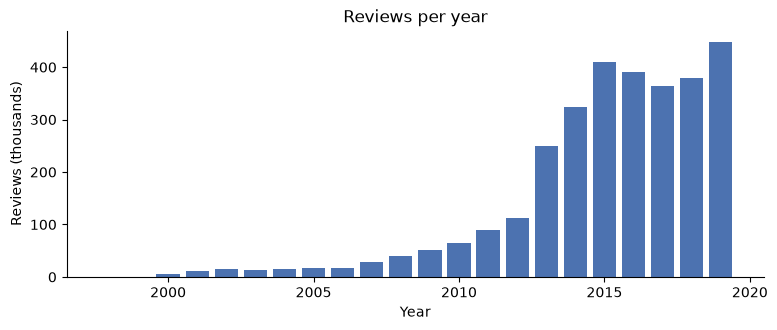

date,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,...,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
reviews,6,458,4825,10832,14349,14130,15269,16678,16467,28768,...,64491,90309,112097,249524,323573,410413,390297,364174,379551,447400


In [19]:
year_counts = df['date'].dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(year_counts.index, year_counts.values / 1e3, color='#4C72B0')
ax.set_xlabel('Year')
ax.set_ylabel('Reviews (thousands)')
ax.set_title('Reviews per year')
plt.show()
year_counts.to_frame('reviews').T

In [20]:
sample_text = audit_sample['text'].fillna('')
sample_title = audit_sample['title'].fillna('')
non_ascii_share = sample_text.str.count(r'[^\x00-\x7f]') / sample_text.str.len().clip(lower=1)
common_words = r'\b(?:the|and|is|it|to|of|this|you|for|with|but|was|not|are|have|game)\b'

pd.Series({
    'text contains HTML tags such as <br />': sample_text.str.contains(r'<[^>]+>', regex=True).mean(),
    'text contains a URL': sample_text.str.contains(r'https?://|www\.', regex=True).mean(),
    'text with more than 30% non-ASCII characters': (non_ascii_share > 0.3).mean(),
    'text without any common English word': (~sample_text.str.contains(common_words, case=False, regex=True)).mean(),
    'text shorter than 3 characters': (sample_text.str.strip().str.len() < 3).mean(),
    'title shorter than 3 characters': (sample_title.str.strip().str.len() < 3).mean(),
}).to_frame('share of audit_sample').style.format('{:.2%}')

,share of audit_sample
text contains HTML tags such as,16.03%
text contains a URL,0.08%
text with more than 30% non-ASCII characters,0.10%
text without any common English word,12.74%
text shorter than 3 characters,0.37%
title shorter than 3 characters,0.40%


The English check is a rough estimate. A review with no common English word is either written in another language or very short, so the number is an upper bound for non-English text.

**Findings for 3.4.**

- All values respect the dataset's own rules: no rating outside 1 to 5, no fractional rating, no negative vote count, no timestamp before 1996, and no timestamp on or after the cutoff.
- The data starts in 1998 and ends on 31 December 2019. Volume grows over time: 84.3% of the reviews were written from 2013 to 2019, and every year before 2007 has under 30,000 reviews.
- In the 500,000 review sample, 16.03% of texts contain HTML tags, and 0.08% contain a URL.
- 12.74% of texts contain no common English word. This mixes non-English reviews with very short reviews, so it is an upper bound for non-English text. Only 0.10% of texts are mostly non-ASCII.
- Very short text (under 3 characters) is rare: 0.37% of texts and 0.40% of titles.

### 3.5 Outliers

An outlier is a value far from the rest of its column. This check only finds them. Section 4 decides what to do. The standard 1.5 x IQR rule is applied to the review length and to `helpful_vote`, and then tested for whether it can be trusted on each column.

In [21]:
lengths = pd.DataFrame({
    'title_chars': df['title'].fillna('').str.len(),
    'text_chars': df['text'].fillna('').str.len(),
})
quantiles = [0.01, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999]
summary = pd.concat([
    lengths.quantile(quantiles).T,
    df[['helpful_vote']].quantile(quantiles).T,
])
summary['max'] = [lengths['title_chars'].max(), lengths['text_chars'].max(), df['helpful_vote'].max()]
summary

,0.01,0.25,0.5,0.75,0.9,0.99,0.999,max
title_chars,3.0,10.0,16.0,31.0,49.0,88.0,126.000,605
text_chars,4.0,45.0,131.0,328.0,796.0,3490.0,8435.938,36893
helpful_vote,0.0,0.0,0.0,1.0,3.0,21.0,119.000,10369


In [22]:
rows = []
for name, s in [('title_chars', lengths['title_chars']), ('text_chars', lengths['text_chars']),
                ('helpful_vote', df['helpful_vote'])]:
    q1, q3 = s.quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    rows.append({'column': name, 'q1': q1, 'q3': q3, 'upper_fence': upper,
                 'above_fence': (s > upper).sum(), 'above_fence_pct': (s > upper).mean() * 100,
                 'zero_pct': (s == 0).mean() * 100})
pd.DataFrame(rows).set_index('column')

,q1,q3,upper_fence,above_fence,above_fence_pct,zero_pct
column,,,,,,
title_chars,10.0,31.0,62.5,131376,4.315855,0.000000
text_chars,45.0,328.0,752.5,325141,10.681261,0.010611
helpful_vote,0.0,1.0,2.5,308417,10.131858,71.352108


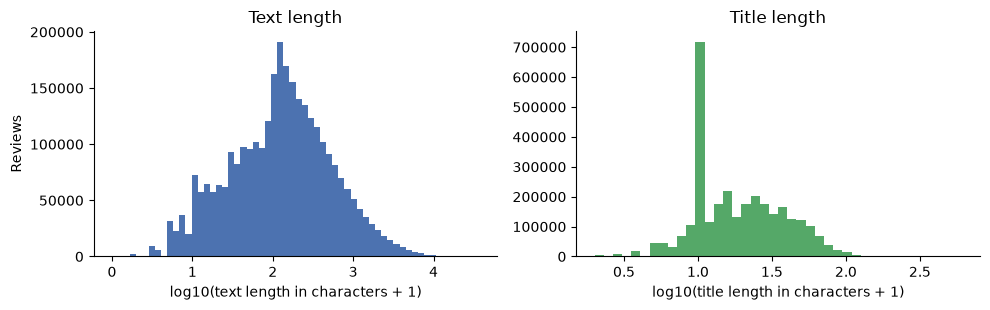

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(np.log10(lengths['text_chars'] + 1), bins=60, color='#4C72B0')
axes[0].set_xlabel('log10(text length in characters + 1)')
axes[0].set_ylabel('Reviews')
axes[0].set_title('Text length')
axes[1].hist(np.log10(lengths['title_chars'] + 1), bins=40, color='#55A868')
axes[1].set_xlabel('log10(title length in characters + 1)')
axes[1].set_title('Title length')
plt.tight_layout()
plt.show()

**Findings for 3.5.**

- Text length is right-skewed on a log scale: median 131 characters, 75th percentile 328, 99th percentile 3,490 and a maximum of 36,893.
- Titles are short: median 16 characters, 99th percentile 88 and a maximum of 605. The title histogram has a sharp spike at about 10 characters. That is the length of default titles such as "Five Stars", which is examined in 3.7.
- The 1.5 x IQR rule flags 10.68% of texts (above 752.5 characters), 4.32% of titles (above 62.5) and 10.13% of `helpful_vote` values (above 2.5). Such a high share means the rule is not suited to these skewed columns. The flagged long reviews are real reviews, not errors.
- `helpful_vote` is 0 for 71.35% of reviews, so its quartiles are almost meaningless, and it is not used as a feature anyway.
- Extreme lengths are kept. TF-IDF features are length normalised, so a long review does not dominate the model.

### 3.6 Target Distribution

How is the outcome distributed, and what does that mean for evaluation? First the raw star ratings, then the binary target after rating 3 is set aside.

In [24]:
rating_table = df['rating'].value_counts().sort_index().to_frame('reviews')
rating_table['share'] = (rating_table['reviews'] / len(df)).round(4)
rating_table

,reviews,share
rating,,
1.0,338794,0.1113
2.0,155379,0.0510
3.0,230235,0.0756
4.0,447171,0.1469
5.0,1872453,0.6151


In [25]:
binary = label.dropna().map({0.0: 'negative (1 to 2 stars)', 1.0: 'positive (4 to 5 stars)'}).value_counts()
binary_table = binary.to_frame('reviews')
binary_table['share'] = (binary_table['reviews'] / binary_table['reviews'].sum()).round(4)
print(binary_table)
print(f"\nImbalance ratio (positive per negative): {binary.iloc[0] / binary.iloc[1]:.2f}")
print(f"Accuracy of always answering positive   : {binary_table['share'].max():.2%}")

                         reviews   share
rating                                  
positive (4 to 5 stars)  2319624  0.8244
negative (1 to 2 stars)   494173  0.1756

Imbalance ratio (positive per negative): 4.69
Accuracy of always answering positive   : 82.44%


In [ ]:
by_year = pd.DataFrame({'year': df['date'].dt.year, 'label': label}).dropna()
negative_share = by_year.groupby('year')['label'].agg(reviews='size', negative_share=lambda s: 1 - s.mean())
MIN_YEAR_REVIEWS = 1000
plot_data = negative_share[negative_share['reviews'] >= MIN_YEAR_REVIEWS]

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(plot_data.index, plot_data['negative_share'] * 100, marker='o', color='#C44E52')
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel('Year')
ax.set_ylabel('Negative reviews (%)')
ax.set_title(f'Share of negative reviews per year (years with at least {MIN_YEAR_REVIEWS:,} rated reviews)')
plt.show()
negative_share.round(4).astype(object).T

**Findings for 3.6.**

**Raw rating (five values)**
- 5 stars: 1,872,453 reviews (61.51%); 4 stars: 447,171 (14.69%); 3 stars: 230,235 (7.56%); 2 stars: 155,379 (5.10%); 1 star: 338,794 (11.13%).

**Binary target (rating 3 set aside)**
- 2,813,797 rated reviews remain: 2,319,624 positive (82.44%) and 494,173 negative (17.56%), about 4.69 positive reviews for every negative one.
- A model that always answers positive would reach 82.44% accuracy and still find no complaint. Macro-F1 is used for that reason, and the negative class needs attention (class weights and threshold choice).

**Over time**
- The negative share changes with the year, from about 15% (2014) to 23.4% (2006) among years with at least 1,000 rated reviews. It was 15.3% in 2015 and 17.6% in 2019.
- Because the mix changes over time, a time based split is the honest way to measure performance, and the results are checked by year in Section 9.

### 3.7 Possible Leakage

Leakage means the model gets information it would not have at prediction time, or information that reveals the answer. The model is meant to score a new review, so only the title and the text are allowed as inputs. These checks look at the structure of the data for risks.

- `rating` defines the label, so it can never be an input.
- `helpful_vote` is only known after other users have read the review, and `verified_purchase` is not part of the review text. Neither is used.
- The star rating may be written inside the title or the text. Many titles are the default star text, for example "Five Stars" or "One Star", which is the label in words.
- The same reviewer, the same product or the same text can appear on both sides of a split.

The overlap checks use a time based split on the rated reviews (oldest 70% for training, next 15% for validation, newest 15% for test). This is the split planned for the model and is only used here to measure overlap.

In [27]:
default_title = r'^\s*(?:[1-5](?:\.0)?\s*(?:out of 5\s*)?stars?|(?:one|two|three|four|five)\s*stars?)\s*[.!]*\s*$'
rating_in_text = r'\b(?:[0-5](?:\.\d)?\s*(?:/|out of)\s*(?:5|10)|[1-5]\s*(?:stars?|star rating)|(?:one|two|three|four|five)\s*stars?)\b'

sample_label = label.loc[audit_sample.index]
rated_mask = sample_label.notna()
class_name = sample_label.map({0.0: 'negative', 1.0: 'positive'})

checks = pd.DataFrame({
    'title is a default star title': audit_sample['title'].fillna('').str.contains(default_title, case=False, regex=True),
    'title mentions a rating': audit_sample['title'].fillna('').str.contains(rating_in_text, case=False, regex=True),
    'text mentions a rating': audit_sample['text'].fillna('').str.contains(rating_in_text, case=False, regex=True),
})[rated_mask]

by_class = checks.groupby(class_name[rated_mask]).mean()
by_class.insert(0, 'reviews', class_name[rated_mask].value_counts())
print(by_class.round(4).to_string())

default_rows = checks['title is a default star title']
print(f"\nReviews with a default star title            : {default_rows.sum():,} ({default_rows.mean():.2%} of rated reviews)")
print(f"Share of those that are positive             : {sample_label[rated_mask][default_rows].mean():.2%}")

          reviews  title is a default star title  title mentions a rating  text mentions a rating
rating                                                                                           
negative    80916                         0.1158                   0.1191                  0.0394
positive   381216                         0.2235                   0.2258                  0.0270

Reviews with a default star title            : 94,560 (20.46% of rated reviews)
Share of those that are positive             : 90.09%


In [28]:
rated = df.loc[~is_rated_3, ['timestamp', 'user_id', 'parent_asin']].copy()
rated['norm'] = pd.util.hash_pandas_object(norm_text[rated.index], index=False)
t70, t85 = rated['timestamp'].quantile([0.70, 0.85])

part = pd.Series('train', index=rated.index)
part[rated['timestamp'] > t70] = 'validation'
part[rated['timestamp'] > t85] = 'test'
earlier = {'validation': ['train'], 'test': ['train', 'validation']}

rows = []
for name, before in earlier.items():
    now = rated[part == name]
    past = rated[part.isin(before)]
    rows.append({
        'split': name,
        'reviews': len(now),
        'reviewer seen before': now['user_id'].isin(set(past['user_id'])).mean(),
        'product seen before': now['parent_asin'].isin(set(past['parent_asin'])).mean(),
        'text seen before': now['norm'].isin(set(past['norm'])).mean(),
    })
pd.DataFrame(rows).set_index('split').style.format({'reviews': '{:,.0f}', 'reviewer seen before': '{:.2%}',
                                                    'product seen before': '{:.2%}', 'text seen before': '{:.2%}'})

,reviews,reviewer seen before,product seen before,text seen before
split,,,,
validation,"422,069",23.27%,74.33%,14.80%
test,"422,070",22.08%,77.31%,15.77%


In [29]:
print('Split boundaries:', pd.to_datetime(t70, unit='ms').date(), 'and', pd.to_datetime(t85, unit='ms').date())
print(part.value_counts()[['train', 'validation', 'test']])
del rated, part

Split boundaries: 2017-10-19 and 2018-12-31
train         1969658
validation     422069
test           422070
Name: count, dtype: int64


**Findings for 3.7.**

**Default star titles**
- 20.46% of rated reviews (94,560 in the sample) have a title that is only the star rating in words, such as "Five Stars". That is 22.35% of positive reviews and 11.58% of negative reviews. Among these reviews, 90.09% are positive.
- Titles that mention a rating overall behave the same (22.58% of positive and 11.91% of negative reviews). In the text, a rating mention is much rarer (2.70% of positive and 3.94% of negative reviews).
- A default title restates the label, so a model could read the answer from the title alone and look better than it really is. The risk sits in the title, not in the text. This is handled in Section 4.

**Reviewers, products and texts across a time split (oldest 70% train, next 15% validation, newest 15% test)**
- Split boundaries: 2017-10-19 and 2018-12-31, giving 1,969,658 training, 422,069 validation and 422,070 test reviews.
- Reviewer seen before: 23.27% of validation and 22.08% of test reviews.
- Product seen before: 74.33% of validation and 77.31% of test reviews.
- Text seen before: 14.80% of validation and 15.77% of test reviews. These are mostly short generic phrases.
- Product overlap is natural and not harmful for a sentiment model, because the same product can receive new reviews. Repeated generic texts are a mild optimistic bias, so Section 9 also reports the score on reviews whose text was not seen in training.
- `rating`, `helpful_vote` and `verified_purchase` are excluded from the inputs.

### 3.8 Summary of Issues and Planned Treatment

The plan below is confirmed or adjusted in Section 4.

| # | Issue | Evidence | Planned treatment |
|---|---|---|---|
| 1 | Rating 3 is ambiguous | 230,235 reviews (7.56%) | Remove, as the assignment states |
| 2 | Blank review text | 325 reviews, all with a title | Remove |
| 3 | Exact duplicate rows | 35,056 rows (1.15%) | Remove, keeping the first occurrence |
| 4 | Repeated generic texts | 17.22% of rated reviews, 868 texts with both labels | Keep, since they are real opinions. Report the score on unseen texts in Section 9 |
| 5 | HTML tags in text | 16.03% of the sample | Replace tags with a space |
| 6 | URLs | 0.08% of the sample | Keep, no action needed |
| 7 | Non-English text | Up to 12.74% of the sample | Keep and Report the share |
| 8 | Default star titles that restate the label | 20.46% of rated reviews, 90.09% of them positive | Mask the title in these cases and test the effect on the score |
| 9 | Long reviews flagged by the IQR rule | 10.68% of texts above 752.5 characters | Keep, no capping |
| 10 | Strong class imbalance | 82.44% positive, 17.56% negative | Macro-F1, class weights and a threshold chosen on validation data |
| 11 | Negative share changes over time | About 15% to 23% across years | Time based split and results by year |
| 12 | Reviewer, product and text overlap across a time split | 22% to 23% of reviewers, 74% to 77% of products and 15% to 16% of texts seen before | Accept for reviewers and products. Report the unseen text score |
| 13 | Fields not allowed as inputs | `rating`, `helpful_vote`, `verified_purchase` | Excluded from the features |